## Stap 1: Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

import os

In [2]:
# Deze cel maakte van de originele diabetes.csv het bestand diabetes_dirty.csv.
# diabetes.csv hebben we niet gekregen, diabetes_dirty.csv wel -> deze cel moet niet meer uitgevoerd worden.

# # 1. Originele data inlezen
# pima = pd.read_csv("diabetes.csv")

# # 2. Vervuilen van de dataset voor onderwijsdoeleinden
# np.random.seed(42)
# pima_dirty = pima.copy()

# # A. Biologisch onmogelijke nulwaarden injecteren (frequent in Pima Diabetes data)
# cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
# for col in cols_with_zero:
#     mask = np.random.rand(len(pima_dirty)) < 0.05
#     pima_dirty.loc[mask, col] = 0

# # B. Echte ontbrekende waarden (NaN) injecteren
# for col in ['BMI', 'Age']:
#     mask = np.random.rand(len(pima_dirty)) < 0.03
#     pima_dirty.loc[mask, col] = np.nan

# # C. Typo's / incorrecte datatypes (strings in een numerieke kolom)
# pima_dirty.loc[12, 'Glucose'] = '140_err'
# pima_dirty.loc[25, 'BloodPressure'] = 'missing'

# # D. Dubbele rijen (duplicates) toevoegen
# duplicates = pima_dirty.sample(n=8, random_state=42)
# pima_dirty = pd.concat([pima_dirty, duplicates], ignore_index=True)

# # Opslaan als het vervuilde bestand voor de studenten
# pima_dirty.to_csv("diabetes_dirty.csv", index=False)
# print("Vervuilde dataset succesvol aangemaakt (diabetes_dirty.csv).")

## Stap 2: Data

1. Duplicaten verwijderen.
2. Datatypes herstellen: tekstwaarden omzetten naar numeriek (errors='coerce' vervangt ongeldige strings door NaN).
3. Onmogelijke nulwaarden omzetten naar NaN: een bloeddruk, BMI of glucosewaarde van 0 is fysiologisch onmogelijk en dient als ontbrekende data behandeld te worden.
4. Imputatie: ontbrekende waarden invullen met de mediaan van de respectievelijke kolom (robuust tegen uitschieters).

In [3]:
pima = pd.read_csv("diabetes_dirty.csv")
pima.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50.0,1
1,1,85,66.0,29,102.5,26.6,0.351,31.0,0
2,8,183,64.0,32,169.5,23.3,0.672,32.0,1
3,1,89,66.0,23,94.0,28.1,0.167,21.0,0
4,0,137,40.0,35,168.0,43.1,2.288,33.0,1
5,5,116,74.0,27,102.5,25.6,0.201,30.0,0
6,3,78,50.0,32,88.0,31.0,0.248,26.0,1
7,10,115,70.0,27,102.5,35.3,0.134,29.0,0
8,2,197,70.0,45,543.0,30.5,0.158,53.0,1
9,8,125,96.0,32,169.5,34.3,0.232,54.0,1


In [4]:
pima.info()
# pima.describe()
# pima.duplicated().sum()  # Aantal dubbele rijen
# pima.isnull().sum()  # Aantal ontbrekende waarden per kolom

<class 'pandas.DataFrame'>
RangeIndex: 776 entries, 0 to 775
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               776 non-null    int64  
 1   Glucose                   776 non-null    str    
 2   BloodPressure             776 non-null    str    
 3   SkinThickness             776 non-null    int64  
 4   Insulin                   776 non-null    float64
 5   BMI                       752 non-null    float64
 6   DiabetesPedigreeFunction  776 non-null    float64
 7   Age                       757 non-null    float64
 8   Outcome                   776 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 54.7 KB


In [5]:
pima.columns[0:8]

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')

In [6]:
pima = pima.drop_duplicates().reset_index(drop=True)

# 2. Zorg dat alle featurekolommen numeriek zijn (foute invoer wordt NaN)
feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for col in feature_cols:
    pima[col] = pd.to_numeric(pima[col], errors='coerce')

# 3. Vervang biologisch onmogelijke nullen door NaN
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
pima[invalid_zero_cols] = pima[invalid_zero_cols].replace(0, np.nan)

# 4. Imputatie van ontbrekende waarden aan de hand van de kolommediaan
for col in feature_cols:
    median_val = pima[col].median()
    pima[col] = pima[col].fillna(median_val)

print("Aantal resterende NaN-waarden per kolom:")
print(pima.isna().sum())

Aantal resterende NaN-waarden per kolom:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
#split dataset in features and target variable
feature_cols = pima.columns[0:8]
X = pima[feature_cols] # Features
y = pima.Outcome.astype(int) # Target variable

## Stap 3: Splitsen in Train en Test

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) 

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")
print("Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is")

Omvang trainingset: 614 | Omvang testset: 154
Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is


## Stap 4: Uitgebreide evaluatiefunctie met visualisaties

Om herhaling te voorkomen en interpretaties te standaardiseren, vatten we de evaluatietechnieken samen in een herbruikbare functie `evalueer_model`. Deze genereert:

* Confusion Matrix (Heatmap): overzicht van True Positives (TP), False Positives (FP), True Negatives (TN) en False Negatives (FN).

* Classification Report: Accuracy, Precision, Recall en F1-score.

* ROC-curve & AUC: toont het onderscheidend vermogen over alle mogelijke drempelwaarden.

In [9]:
def evalueer_model(model, X_test, y_test, model_naam="Model"):
    # Voorspellingen
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # 1. Metrieken
    acc = metrics.accuracy_score(y_test, y_pred)
    prec = metrics.precision_score(y_test, y_pred, zero_division=0)
    rec = metrics.recall_score(y_test, y_pred, zero_division=0)
    f1 = metrics.f1_score(y_test, y_pred, zero_division=0)
    auc_score = metrics.roc_auc_score(y_test, y_pred_proba)
    
    print(f"\n{'='*20} Evaluatierapport: {model_naam} {'='*20}")
    print(metrics.classification_report(y_test, y_pred, target_names=['Geen Diabetes (0)', 'Diabetes (1)']))
    print(f"ROC-AUC Score: {auc_score:.4f}\n")
    
    # 2. Visualisaties (Confusion Matrix & ROC-curve)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    # Confusion Matrix
    cm = metrics.confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Geen Diabetes', 'Diabetes'],
                yticklabels=['Geen Diabetes', 'Diabetes'])
    axes[0].set_title(f'Confusion Matrix - {model_naam}')
    axes[0].set_xlabel('Voorspeld label')
    axes[0].set_ylabel('Werkelijk label')
    
    # ROC-Curve
    fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-curve (AUC = {auc_score:.2f})')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Willekeurige gokker (AUC = 0.50)')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate (1 - Specificiteit)')
    axes[1].set_ylabel('True Positive Rate (Recall / Sensitiviteit)')
    axes[1].set_title(f'ROC-curve - {model_naam}')
    axes[1].legend(loc="lower right")
    
    plt.tight_layout()
    plt.show()
    
    return {
        'Model': model_naam,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'ROC-AUC': auc_score
    }

## Stap 5: Train het model

We schrijven één algemene functie `train_en_evalueer_pipeline` waarmee we een specifiek algoritme instantiëren, trainen, evalueren en de resultaten teruggeven.

In [10]:
def train_en_evalueer_pipeline(model_type, X_train, y_train, X_test, y_test, **hyperparameters):
    """
    Parameters:
    - model_type: 'logreg', 'decision_tree', of 'random_forest'
    - hyperparameters: optionele parameters voor het gekozen model
    """
    if model_type == 'logreg':
        # max_iter verhoogd om convergentiewaarschuwingen te voorkomen
        model = LogisticRegression(random_state=42, max_iter=1000, **hyperparameters)
        naam = "Logistische Regressie"
        
    elif model_type == 'decision_tree':
        # max_depth begrensd om overfitting tegen te gaan
        model = DecisionTreeClassifier(random_state=42, max_depth=4, **hyperparameters)
        naam = "Decision Tree"
        
    elif model_type == 'random_forest':
        model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, **hyperparameters)
        naam = "Decision / Random Forest"
        
    else:
        raise ValueError("Ongeldig model_type. Kies uit: 'logreg', 'decision_tree', 'random_forest'.")
        
    # Model fitten
    model.fit(X_train, y_train)
    
    # Model evalueren
    resultaten = evalueer_model(model, X_test, y_test, model_naam=naam)
    
    return model, resultaten

## Stap 6: Evaluatie


==================== Evaluatierapport: Logistische Regressie ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.76      0.80      0.78       100
     Diabetes (1)       0.59      0.54      0.56        54

         accuracy                           0.71       154
        macro avg       0.68      0.67      0.67       154
     weighted avg       0.70      0.71      0.70       154

ROC-AUC Score: 0.8269



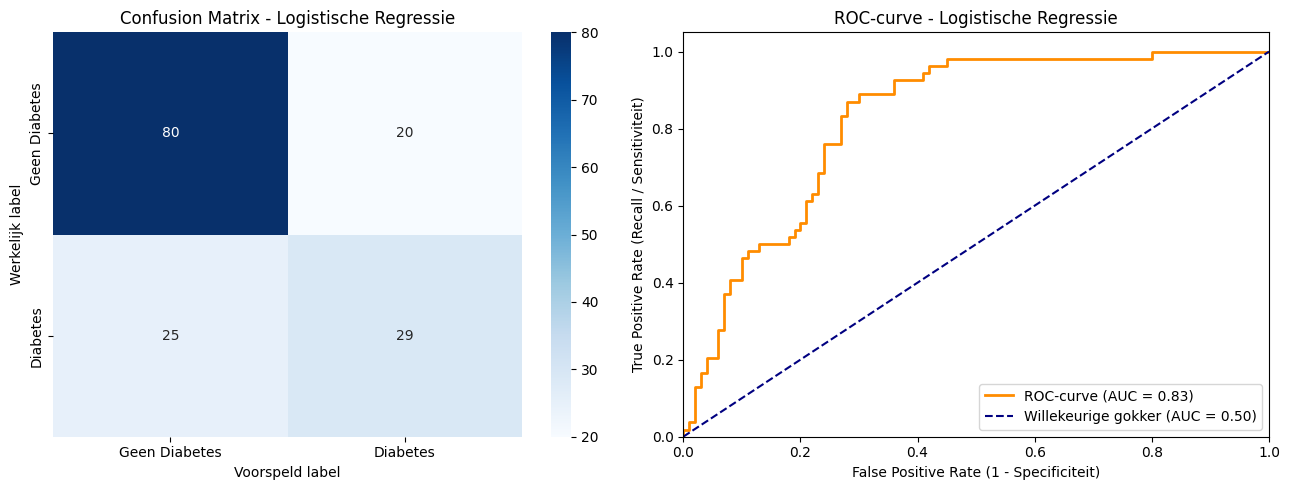


==================== Evaluatierapport: Decision Tree ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.84      0.91      0.88       100
     Diabetes (1)       0.80      0.69      0.74        54

         accuracy                           0.83       154
        macro avg       0.82      0.80      0.81       154
     weighted avg       0.83      0.83      0.83       154

ROC-AUC Score: 0.9246



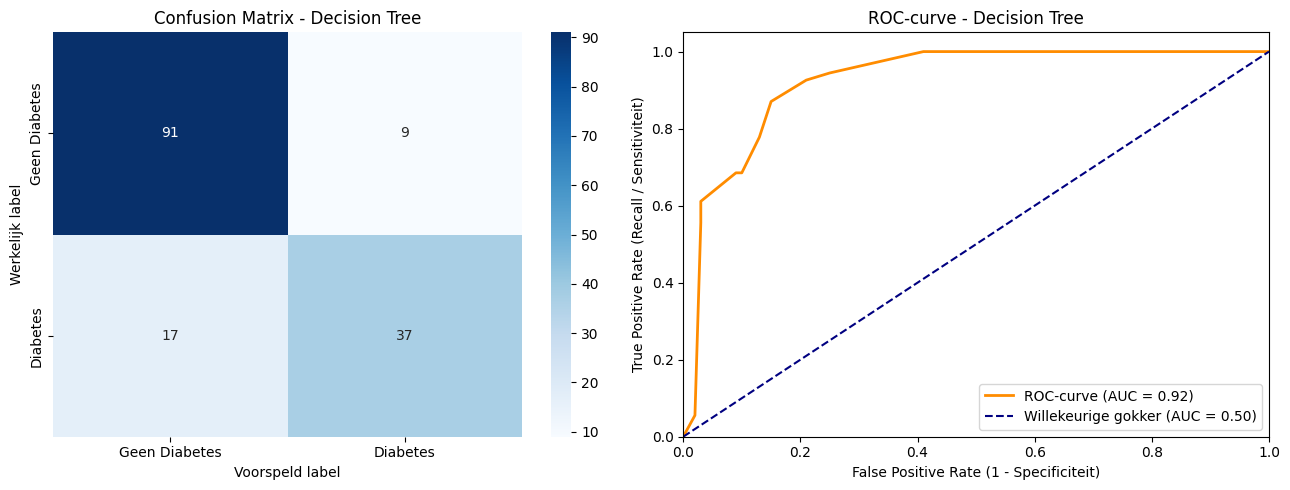


==================== Evaluatierapport: Decision / Random Forest ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.89      0.90      0.90       100
     Diabetes (1)       0.81      0.80      0.80        54

         accuracy                           0.86       154
        macro avg       0.85      0.85      0.85       154
     weighted avg       0.86      0.86      0.86       154

ROC-AUC Score: 0.9370



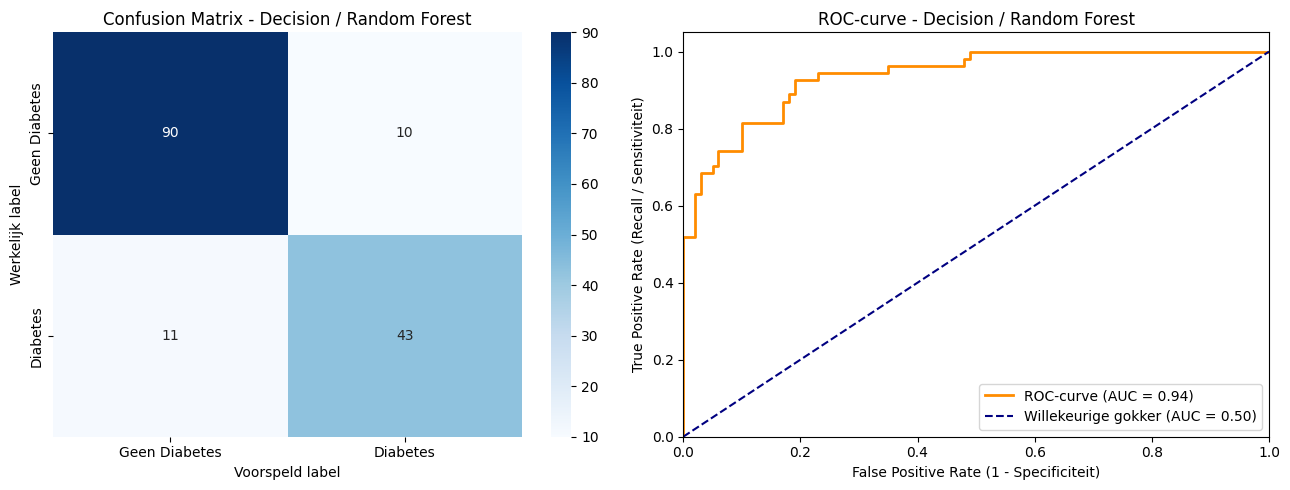

In [11]:
resultaten_lijst = []

# 1. Logistische Regressie
model_lr, res_lr = train_en_evalueer_pipeline('logreg', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_lr)

# 2. Decision Tree
model_dt, res_dt = train_en_evalueer_pipeline('decision_tree', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_dt)

# 3. Decision / Random Forest
model_rf, res_rf = train_en_evalueer_pipeline('random_forest', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_rf)

## Stap 7: Vergelijkende evaluatie & conclusie

                          Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                   
Logistische Regressie       0.7078     0.5918  0.5370    0.5631   0.8269
Decision Tree               0.8312     0.8043  0.6852    0.7400   0.9246
Decision / Random Forest    0.8636     0.8113  0.7963    0.8037   0.9370


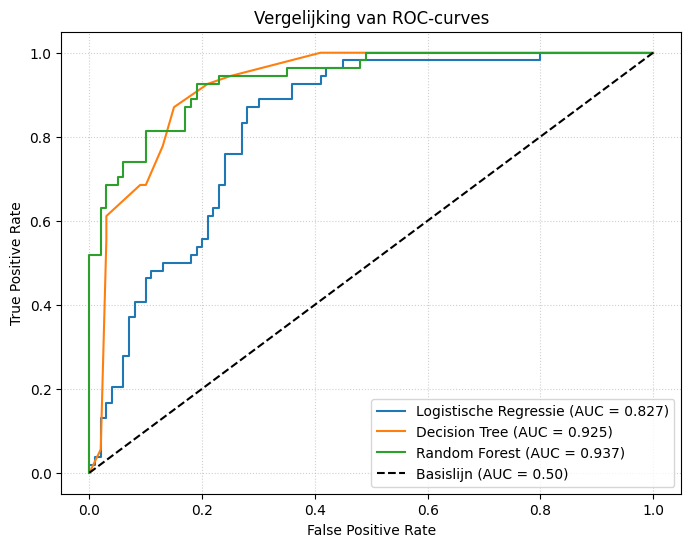

In [12]:
# Resultaten samenbrengen in een overzichtelijke DataFrame
df_vergelijking = pd.DataFrame(resultaten_lijst).set_index('Model')
print(df_vergelijking.round(4))

# Vergelijkende visualisatie van ROC-curves
plt.figure(figsize=(8, 6))
modellen = [('Logistische Regressie', model_lr), ('Decision Tree', model_dt), ('Random Forest', model_rf)]

for naam, m in modellen:
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    auc_val = metrics.roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{naam} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Basislijn (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Vergelijking van ROC-curves')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Inhoudelijke interpretatie:
#### **Logistische Regressie:**

* Presteert sterk en consistent op deze dataset omdat veel van de diabetesindicatoren (zoals Glucose en Leeftijd) een vrijwel lineair stijgend verband tonen met het risico op diabetes. Het levert een stabiele, hoge ROC-AUC op.

#### **Decision Tree:**

* Zeer inzichtelijk doordat de beslisregels visueel te volgen zijn, maar gevoelig voor variantie en overfitting. De ROC-curve verloopt vaak hoekiger en de algemene AUC ligt lager dan bij de overige methoden.

#### **Decision / Random Forest:**

* Combineert meerdere bomen via bagging en feature randomness. Hierdoor worden de uitschieters en instabiliteit van een enkele boom opgevangen. Het levert doorgaans de hoogste of meest gebalanceerde Recall en F1-score, wat in een medische context van levensbelang is: het minimaliseren van False Negatives.

#### **Eindoordeel:**

* Het Random Forest geniet over het algemeen de voorkeur voor robuustheid en generiek voorspellend vermogen, terwijl Logistische Regressie een competitief, snel en zeer verklaarbaar alternatief vormt.

# **Oefening**

## **Context**  
Cardiologen willen een vroegtijdig waarschuwingssysteem ontwikkelen om te bepalen of een patiënt een verhoogd risico heeft op een kransslagaderaandoening (`target: 0 = geen aandoening`, `1 = aanwezig`). Ze hebben een ruwe dataset aangeleverd (`heart_disease_dirty.csv`), maar deze bevat fouten, typfouten en ontbrekende waarden (doktersgeschrift he).

## **Te doorlopen stappen**  
* Stap 1: Data Inspectie & Cleaning (data_stap)
    * Laad heart_disease_dirty.csv in.
    * Verwijder eventuele dubbele rijen (duplicates).
    * Controleer de datatypes van alle kolommen. Corrigeer foutieve tekens/strings (bijv. '?' of tekstfouten in numerieke kolommen zoals chol of trestbps).
    * Inspecteer op fysiologisch onmogelijke waarden (bijv. rustbloeddruk trestbps = 0 of cholesterol chol = 0) en zet deze om naar NaN.* Kies een geschikte imputatiestrategie voor de ontbrekende waarden (bijvoorbeeld mediaan voor scheve numerieke data, of modus voor categorische waarden).
* Stap 2: Trein- en Testsplitsing
    * Splits de data op in kenmerken ($X$) en target ($y$: target).
    * Splits op in een trainingset (80%) en een testset (20%) met random_state=42 en zorg voor stratify=y.
* Stap 3: Pipeline / Modulaire Evaluatiefunctie
    * Schrijf een functie evalueer_model(model, X_test, y_test, model_naam) die:
        * De Confusion Matrix toont als Seaborn heatmap.
        * Het Classification Report (Accuracy, Precision, Recall, F1) afdrukt.
        * De ROC-curve tekent inclusief de AUC-score.
        * Een dictionary met de belangrijkste metrieken retourneert.
* Stap 4: Modellen trainen via een centrale functie
    * Schrijf een functie train_model(model_type, X_train, y_train, **kwargs) die het juiste algoritme instantiëert, traint op X_train en het getrainde model teruggeeft.
    * Train de volgende 3 modellen:
        * Logistische Regressie (Let op: schaal de data met StandardScaler of verhoog max_iter om convergentieproblemen te vermijden).
        * Decision Tree (Stel max_depth in om overfitting te beperken).
        * Random Forest (Kies bijv. n_estimators=100, max_depth=5).
* Stap 5: Conclusie & Klinische Interpretatie
    * Vat de resultaten van de 3 modellen samen in één overzichtstabel en plot de drie ROC-curves in één figuur.
    * Beantwoord de reflectievragen:
        * Welk model haalt de hoogste ROC-AUC?
        * In een medische context: geef je de voorkeur aan een hoge Precision of een hoge Recall voor klasse 1? Waarom?
        * Welk model kies je finaal als beste model voor het ziekenhuis?

## Stap 0: Libraries

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import os

## Stap 1: Data Inspectie & Cleaning

In [14]:
hart = pd.read_csv("heart_disease_dirty.csv")
hart.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,NaN,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,1
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,1
9,53.0,1.0,4.0,140.0,0.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


In [15]:
hart.info()
print("\nAantal dubbele rijen:", hart.duplicated().sum())
print("\nAantal ontbrekende waarden per kolom:")
print(hart.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       309 non-null    float64
 1   sex       309 non-null    float64
 2   cp        309 non-null    float64
 3   trestbps  309 non-null    str    
 4   chol      309 non-null    str    
 5   fbs       309 non-null    float64
 6   restecg   309 non-null    float64
 7   thalach   296 non-null    float64
 8   exang     309 non-null    float64
 9   oldpeak   295 non-null    float64
 10  slope     309 non-null    float64
 11  ca        309 non-null    str    
 12  thal      309 non-null    str    
 13  target    309 non-null    int64  
dtypes: float64(9), int64(1), str(4)
memory usage: 33.9 KB

Aantal dubbele rijen: 6

Aantal ontbrekende waarden per kolom:
age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach     13
exang        0
oldpeak     14
slope    

De kolommen `trestbps`, `chol`, `ca` en `thal` zijn van het type `object`, terwijl het getallen zouden moeten zijn.
We kijken welke tekstwaarden er in die kolommen zitten.

In [16]:
for col in ['trestbps', 'chol', 'ca', 'thal']:
    # Waarden die niet naar een getal omgezet kunnen worden
    foute_waarden = hart[col][pd.to_numeric(hart[col], errors='coerce').isna()]
    print(col, "->", foute_waarden.unique())

trestbps -> <StringArray>
['?']
Length: 1, dtype: str
chol -> <StringArray>
['ERR_320']
Length: 1, dtype: str
ca -> <StringArray>
['?']
Length: 1, dtype: str
thal -> <StringArray>
['?']
Length: 1, dtype: str


We zien `'?'` en `'ERR_320'`. Daarnaast kijken we of er fysiologisch onmogelijke nullen zijn:
een rustbloeddruk (`trestbps`) of cholesterol (`chol`) van 0 kan niet.
Bij kolommen zoals `sex`, `fbs`, `exang`, `ca` of `oldpeak` is 0 wel een geldige waarde.

In [17]:
print("trestbps = 0:", (pd.to_numeric(hart['trestbps'], errors='coerce') == 0).sum())
print("chol = 0:    ", (pd.to_numeric(hart['chol'], errors='coerce') == 0).sum())

trestbps = 0: 17
chol = 0:     19


**Cleaning stappen (met pandas):**

1. Duplicaten verwijderen.
2. Datatypes herstellen: tekstwaarden omzetten naar numeriek (`errors='coerce'` maakt van `'?'` en `'ERR_320'` een NaN).
3. Onmogelijke nulwaarden (`trestbps`, `chol`) omzetten naar NaN.

De ontbrekende waarden (NaN) vullen we hier nog **niet** in. Dat gebeurt verderop in de pipeline met `SimpleImputer`,
zodat de mediaan/modus enkel op de **trainingsdata** berekend wordt (geen data leakage).

In [18]:
# 1. Duplicaten verwijderen
hart = hart.drop_duplicates().reset_index(drop=True)

# 2. Alle featurekolommen numeriek maken (foute invoer wordt NaN)
feature_cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

for col in feature_cols:
    hart[col] = pd.to_numeric(hart[col], errors='coerce')

# 3. Fysiologisch onmogelijke nullen vervangen door NaN
invalid_zero_cols = ['trestbps', 'chol']
hart[invalid_zero_cols] = hart[invalid_zero_cols].replace(0, np.nan)

print("Aantal ontbrekende waarden per kolom (worden in de pipeline ingevuld):")
print(hart.isna().sum())

Aantal ontbrekende waarden per kolom (worden in de pipeline ingevuld):
age          0
sex          0
cp           0
trestbps    18
chol        19
fbs          0
restecg      0
thalach     13
exang        0
oldpeak     14
slope        0
ca           4
thal         2
target       0
dtype: int64


In [19]:
hart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,285.000000,284.000000,303.000000,303.000000,290.000000,303.000000,289.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.901754,247.225352,0.148515,0.990099,149.051724,0.326733,0.999654,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.780078,51.343628,0.356198,0.994971,22.793508,0.469794,1.139886,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,212.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,152.000000,0.000000,0.600000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,274.250000,0.000000,2.000000,165.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


## Stap 2: Train- en Testsplitsing

In [20]:
X = hart[feature_cols]        # Features
y = hart['target'].astype(int)  # Target variable

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")

Omvang trainingset: 242 | Omvang testset: 61


## Stap 2.1: Preprocessing met ColumnTransformer

We splitsen de features op in twee groepen:

* **Numerieke features** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`):
    * `SimpleImputer(strategy='median')`: mediaan, want robuust tegen uitschieters/scheve data.
    * `StandardScaler()`: alles op dezelfde schaal (gemiddelde 0, standaardafwijking 1). Nodig voor Logistische Regressie om convergentieproblemen te vermijden.
* **Categorische features** (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`):
    * `SimpleImputer(strategy='most_frequent')`: modus, want een mediaan of gemiddelde kan een waarde opleveren die niet bestaat (bv. thal = 4.5).

In [21]:
numerieke_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorische_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

def maak_preprocessor():
    # Numeriek: ontbrekende waarden -> mediaan, daarna schalen
    numerieke_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Categorisch: ontbrekende waarden -> meest voorkomende waarde
    categorische_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent'))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ('num', numerieke_pipeline, numerieke_features),
        ('cat', categorische_pipeline, categorische_features)
    ])
    return preprocessor

maak_preprocessor()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## Stap 3: Modulaire Evaluatiefunctie

Zelfde idee als in de cursus: één functie die de Confusion Matrix, het Classification Report en de ROC-curve toont
en een dictionary met de belangrijkste metrieken teruggeeft.

In [22]:
def evalueer_model(model, X_test, y_test, model_naam="Model"):
    # Voorspellingen
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # 1. Metrieken
    acc = metrics.accuracy_score(y_test, y_pred)
    prec = metrics.precision_score(y_test, y_pred, zero_division=0)
    rec = metrics.recall_score(y_test, y_pred, zero_division=0)
    f1 = metrics.f1_score(y_test, y_pred, zero_division=0)
    auc_score = metrics.roc_auc_score(y_test, y_pred_proba)

    print(f"\n{'='*20} Evaluatierapport: {model_naam} {'='*20}")
    print(metrics.classification_report(y_test, y_pred, target_names=['Gezond (0)', 'Hartziekte (1)']))
    print(f"ROC-AUC Score: {auc_score:.4f}\n")

    # 2. Visualisaties (Confusion Matrix & ROC-curve)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Confusion Matrix
    cm = metrics.confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Gezond', 'Hartziekte'],
                yticklabels=['Gezond', 'Hartziekte'])
    axes[0].set_title(f'Confusion Matrix - {model_naam}')
    axes[0].set_xlabel('Voorspeld label')
    axes[0].set_ylabel('Werkelijk label')

    # ROC-curve
    fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-curve (AUC = {auc_score:.2f})')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Willekeurige gokker (AUC = 0.50)')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate (1 - Specificiteit)')
    axes[1].set_ylabel('True Positive Rate (Recall / Sensitiviteit)')
    axes[1].set_title(f'ROC-curve - {model_naam}')
    axes[1].legend(loc="lower right")

    plt.show()

    return {
        'Model': model_naam,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'ROC-AUC': auc_score
    }

## Stap 4: Modellen trainen via een centrale functie

Elk model krijgt een `Pipeline` met 2 stappen: eerst de `preprocessor` (imputatie + schalen), daarna het model.
Zo wordt alles enkel op de trainingsdata gefit, en worden bij `predict` op de testdata automatisch dezelfde stappen toegepast.

In [23]:
def train_model(model_type, X_train, y_train, **kwargs):
    """
    Parameters:
    - model_type: 'logreg', 'decision_tree' of 'random_forest'
    - kwargs: optionele hyperparameters voor het model
    """
    if model_type == 'logreg':
        # max_iter verhoogd om convergentiewaarschuwingen te voorkomen
        model = LogisticRegression(random_state=42, max_iter=1000, **kwargs)
    elif model_type == 'decision_tree':
        # max_depth begrensd om overfitting tegen te gaan
        model = DecisionTreeClassifier(random_state=42, max_depth=4, **kwargs)
    elif model_type == 'random_forest':
        model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, **kwargs)
    else:
        raise ValueError("Ongeldig model_type. Kies uit: 'logreg', 'decision_tree', 'random_forest'.")

    # Preprocessing + model samen in 1 pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', maak_preprocessor()),
        ('model', model)
    ])

    # Pipeline fitten
    pipeline.fit(X_train, y_train)

    return pipeline


==================== Evaluatierapport: Logistische Regressie ====================
                precision    recall  f1-score   support

    Gezond (0)       0.93      0.82      0.87        33
Hartziekte (1)       0.81      0.93      0.87        28

      accuracy                           0.87        61
     macro avg       0.87      0.87      0.87        61
  weighted avg       0.88      0.87      0.87        61

ROC-AUC Score: 0.9556



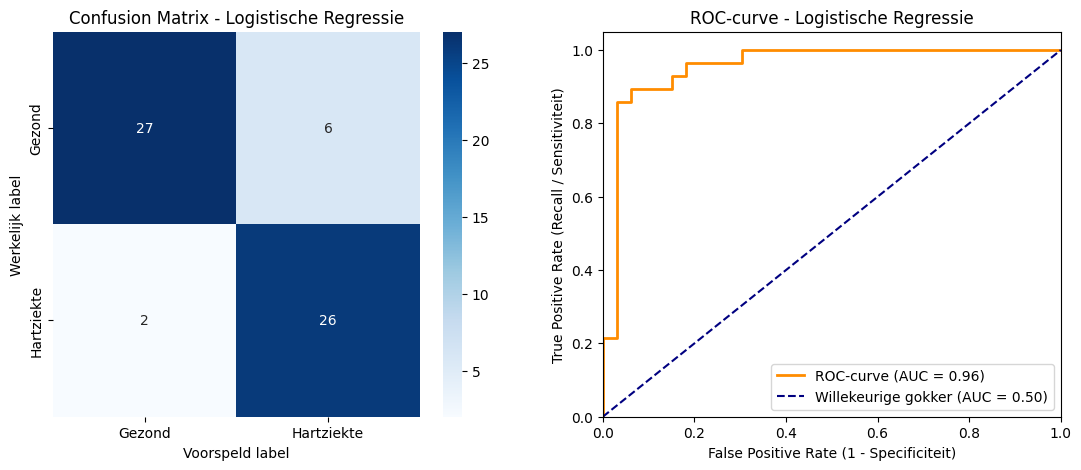


==================== Evaluatierapport: Decision Tree ====================
                precision    recall  f1-score   support

    Gezond (0)       0.83      0.76      0.79        33
Hartziekte (1)       0.74      0.82      0.78        28

      accuracy                           0.79        61
     macro avg       0.79      0.79      0.79        61
  weighted avg       0.79      0.79      0.79        61

ROC-AUC Score: 0.8582



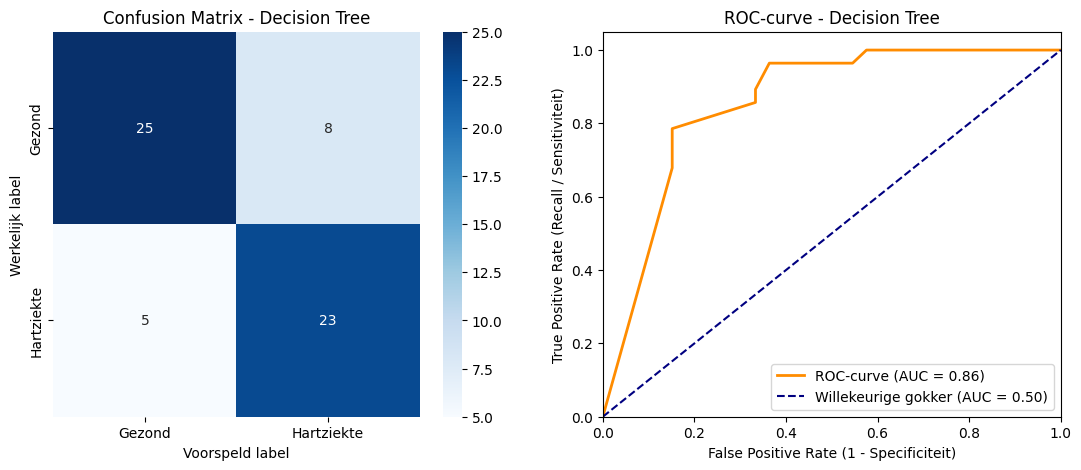


==================== Evaluatierapport: Random Forest ====================
                precision    recall  f1-score   support

    Gezond (0)       0.97      0.91      0.94        33
Hartziekte (1)       0.90      0.96      0.93        28

      accuracy                           0.93        61
     macro avg       0.93      0.94      0.93        61
  weighted avg       0.94      0.93      0.93        61

ROC-AUC Score: 0.9600



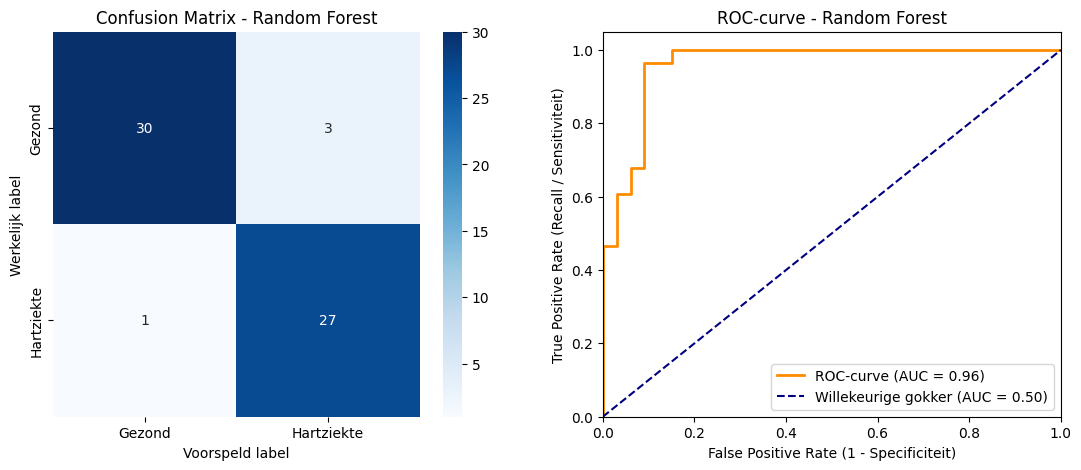

In [24]:
resultaten_lijst = []

# 1. Logistische Regressie
model_lr = train_model('logreg', X_train, y_train)
resultaten_lijst.append(evalueer_model(model_lr, X_test, y_test, "Logistische Regressie"))

# 2. Decision Tree
model_dt = train_model('decision_tree', X_train, y_train)
resultaten_lijst.append(evalueer_model(model_dt, X_test, y_test, "Decision Tree"))

# 3. Random Forest
model_rf = train_model('random_forest', X_train, y_train)
resultaten_lijst.append(evalueer_model(model_rf, X_test, y_test, "Random Forest"))

## Stap 5: Conclusie & Klinische Interpretatie

                       Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                
Logistische Regressie    0.8689     0.8125  0.9286    0.8667   0.9556
Decision Tree            0.7869     0.7419  0.8214    0.7797   0.8582
Random Forest            0.9344     0.9000  0.9643    0.9310   0.9600


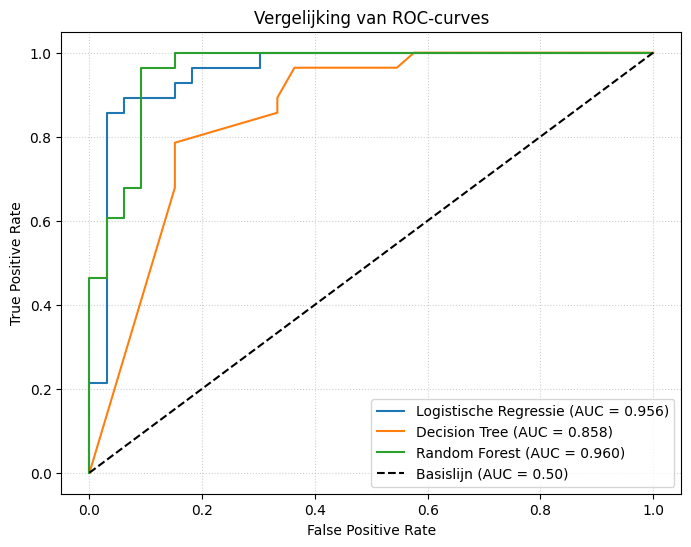

In [25]:
# Resultaten samenbrengen in 1 overzichtstabel
df_vergelijking = pd.DataFrame(resultaten_lijst).set_index('Model')
print(df_vergelijking.round(4))

# De drie ROC-curves in 1 figuur
plt.figure(figsize=(8, 6))
modellen = [('Logistische Regressie', model_lr), ('Decision Tree', model_dt), ('Random Forest', model_rf)]

for naam, m in modellen:
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    auc_val = metrics.roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{naam} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Basislijn (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Vergelijking van ROC-curves')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Reflectievragen

**1. Welk model haalt de hoogste ROC-AUC?**

* **Random Forest** haalt de hoogste ROC-AUC (± 0.960), op de voet gevolgd door **Logistische Regressie** (± 0.956).
* De **Decision Tree** scoort duidelijk lager (± 0.858). Een enkele boom is minder stabiel en geeft maar een paar verschillende kansen terug, daarom is de ROC-curve ook hoekiger.

**2. Hoge Precision of hoge Recall voor klasse 1 (hartziekte)?**

* In een medische context geven we de voorkeur aan een **hoge Recall**.
* Recall = hoeveel van de echte hartpatiënten het model effectief vindt. Een lage recall betekent veel **False Negatives**: zieke patiënten die naar huis gestuurd worden als "gezond". Dat kan levensgevaarlijk zijn.
* Een **False Positive** (gezonde patiënt die als ziek aangeduid wordt) is minder erg: die persoon krijgt extra onderzoeken en daar blijkt dan dat er niets aan de hand is. Dat kost wat tijd en geld, maar geen levens.

**3. Welk model kies je finaal voor het ziekenhuis?**

* Ik kies het **Random Forest**: het heeft de hoogste ROC-AUC, de hoogste accuracy (± 0.90), de hoogste F1-score en een hoge recall voor hartziekte (± 0.93, maar 2 van de 28 zieke patiënten gemist).
* **Logistische Regressie** is een goed alternatief: dezelfde recall (± 0.93), bijna dezelfde AUC, en het is makkelijker uit te leggen aan een arts (via de coëfficiënten). Het verschil met Random Forest zit vooral in iets meer False Positives (lagere precision).
* De **Decision Tree** valt af: laagste scores op alle metrieken.
